# Project :- Food Delivery Time Prediction

# Phase 1 -  Data preprocessing & Feature Engineering

# Import library 

In [1]:
import pandas as pd  # work with tabular data
import numpy as np  # numerical calculations
import matplotlib.pyplot as plt  # create visualizations
import seaborn as sns  # statistical visualizations
import ast  # convert location strings into Python tuples

from sklearn.preprocessing import LabelEncoder, StandardScaler  # encoding and scaling

# Load the dataset

In [4]:
df = pd.read_csv("Food_Delivery_Time_Prediction (4).csv")  # load the dataset

df.head()  # display the first five rows

,Order_ID,Customer_Location,Restaurant_Location,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
0,ORD0001,"(17.030479, 79.743077)","(12.358515, 85.100083)",1.57,Rainy,Medium,4,Medium,Afternoon,Car,4.1,3.0,26.22,1321.10,81.54
1,ORD0002,"(15.398319, 86.639122)","(14.174874, 77.025606)",21.32,Cloudy,Medium,8,Low,Night,Car,4.5,4.2,62.61,152.21,29.02
2,ORD0003,"(15.687342, 83.888808)","(19.594748, 82.048482)",6.95,Snowy,Medium,9,High,Night,Bike,3.3,3.4,48.43,1644.38,64.17
3,ORD0004,"(20.415599, 78.046984)","(16.915906, 78.278698)",13.79,Cloudy,Low,2,Medium,Evening,Bike,3.2,3.7,111.63,541.25,79.23
4,ORD0005,"(14.786904, 78.706532)","(15.206038, 86.203182)",6.72,Rainy,High,6,Low,Night,Bike,3.5,2.8,32.38,619.81,2.34


In [5]:
print("Shape:", df.shape)  # show number of rows and columns

print("\nColumns:")
print(df.columns.tolist())  # show column names

print("\nData Types:")
print(df.dtypes)  # show data types

print("\nMissing Values:")
print(df.isnull().sum())  # count missing values

print("\nDuplicate Rows:", df.duplicated().sum())  # count duplicate rows

Shape: (200, 15)

Columns:
['Order_ID', 'Customer_Location', 'Restaurant_Location', 'Distance', 'Weather_Conditions', 'Traffic_Conditions', 'Delivery_Person_Experience', 'Order_Priority', 'Order_Time', 'Vehicle_Type', 'Restaurant_Rating', 'Customer_Rating', 'Delivery_Time', 'Order_Cost', 'Tip_Amount']

Data Types:
Order_ID                          str
Customer_Location                 str
Restaurant_Location               str
Distance                      float64
Weather_Conditions                str
Traffic_Conditions                str
Delivery_Person_Experience      int64
Order_Priority                    str
Order_Time                        str
Vehicle_Type                      str
Restaurant_Rating             float64
Customer_Rating               float64
Delivery_Time                 float64
Order_Cost                    float64
Tip_Amount                    float64
dtype: object

Missing Values:
Order_ID                      0
Customer_Location             0
Restaurant_Location

In [6]:
df = df.drop(columns=["Order_ID"])  # remove unique order ID

In [7]:
df[["Customer_Latitude", "Customer_Longitude"]] = df["Customer_Location"].apply(
    lambda x: pd.Series(ast.literal_eval(x))
)  # extract customer latitude and longitude

df[["Restaurant_Latitude", "Restaurant_Longitude"]] = df["Restaurant_Location"].apply(
    lambda x: pd.Series(ast.literal_eval(x))
)  # extract restaurant latitude and longitude

In [9]:
# Check 

df[
    [
        "Customer_Latitude",
        "Customer_Longitude",
        "Restaurant_Latitude",
        "Restaurant_Longitude"
    ]
].head()

,Customer_Latitude,Customer_Longitude,Restaurant_Latitude,Restaurant_Longitude
0,17.030479,79.743077,12.358515,85.100083
1,15.398319,86.639122,14.174874,77.025606
2,15.687342,83.888808,19.594748,82.048482
3,20.415599,78.046984,16.915906,78.278698
4,14.786904,78.706532,15.206038,86.203182


# Calculate Haversine Distance 


In [10]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  # Earth's radius in kilometers

    lat1 = np.radians(lat1)  # convert customer latitude to radians
    lon1 = np.radians(lon1)  # convert customer longitude to radians
    lat2 = np.radians(lat2)  # convert restaurant latitude to radians
    lon2 = np.radians(lon2)  # convert restaurant longitude to radians

    dlat = lat2 - lat1  # latitude difference
    dlon = lon2 - lon1  # longitude difference

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )  # Haversine calculation

    c = 2 * np.arcsin(np.sqrt(a))  # angular distance

    return R * c  # return distance in kilometers

In [11]:
# Now create the feature 

df["Haversine_Distance"] = haversine_distance(
    df["Customer_Latitude"],
    df["Customer_Longitude"],
    df["Restaurant_Latitude"],
    df["Restaurant_Longitude"]
)  # calculate geographical distance


In [12]:
# Check 
df[["Distance", "Haversine_Distance"]].head()

,Distance,Haversine_Distance
0,1.57,775.651198
1,21.32,1042.385597
2,6.95,476.220706
3,13.79,389.912629
4,6.72,806.505886


# Create rush - hour feature 

In [13]:
df["Rush_Hour"] = df["Order_Time"].isin(
    ["Morning", "Evening"]
).astype(int)  # 1 = rush hour, 0 = non-rush hour

In [14]:
df[["Order_Time", "Rush_Hour"]].head(10)

,Order_Time,Rush_Hour
0,Afternoon,0
1,Night,0
2,Night,0
3,Evening,1
4,Night,0
5,Evening,1
6,Evening,1
7,Evening,1
8,Night,0
9,Afternoon,0


# Create Fast / Delayed target 

This is very important 


In [15]:
delivery_time_median = df["Delivery_Time"].median()  # calculate median delivery time

print("Median Delivery Time:", delivery_time_median)

Median Delivery Time: 72.775


In [16]:
# Create the target 
df["Delivery_Status"] = np.where(
    df["Delivery_Time"] <= delivery_time_median,
    "Fast",
    "Delayed"
)  # classify deliveries into Fast or Delayed

In [17]:
# Check 
df["Delivery_Status"].value_counts()

Delivery_Status
Fast       100
Delayed    100
Name: count, dtype: int64

In [18]:
# Encode it 
df["Target"] = df["Delivery_Status"].map({
    "Fast": 0,
    "Delayed": 1
})  # convert target into numerical labels

# Weather Impact analysis 

In [19]:
weather_analysis = df.groupby("Weather_Conditions")["Delivery_Time"].agg(
    ["mean", "median", "min", "max"]
)  # calculate delivery-time statistics for each weather condition

weather_analysis

,mean,median,min,max
Weather_Conditions,,,,
Cloudy,69.786667,68.205,18.67,118.26
Rainy,73.058947,79.090,15.23,119.46
Snowy,69.191250,72.285,15.42,115.32
Sunny,69.479434,72.910,16.48,119.67


 # Visualize

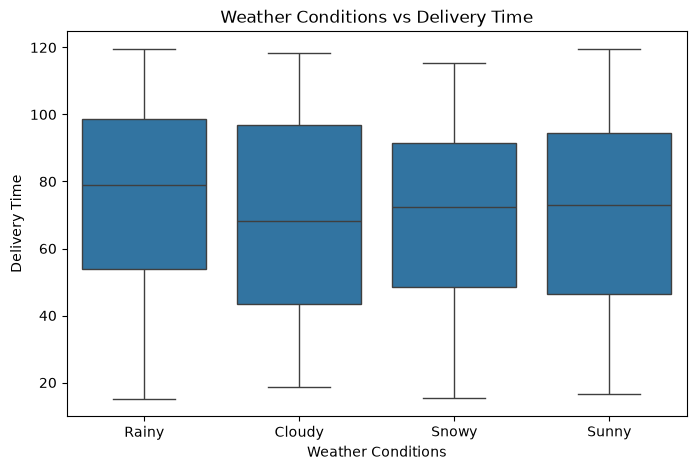

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Weather_Conditions",
    y="Delivery_Time"
)

plt.title("Weather Conditions vs Delivery Time")
plt.xlabel("Weather Conditions")
plt.ylabel("Delivery Time")
plt.show()

# Traffic impact analysis

In [21]:
traffic_analysis = df.groupby("Traffic_Conditions")["Delivery_Time"].agg(
    ["mean", "median", "min", "max"]
)  # calculate delivery-time statistics for traffic

traffic_analysis

,mean,median,min,max
Traffic_Conditions,,,,
High,67.567255,64.180,15.23,119.46
Low,71.927284,77.060,18.89,119.67
Medium,70.984559,71.105,16.48,118.26


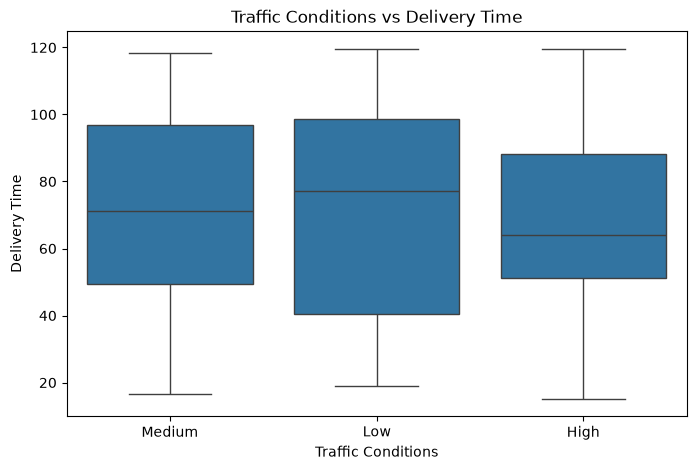

In [23]:
# Visualization

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Traffic_Conditions",
    y="Delivery_Time"
)

plt.title("Traffic Conditions vs Delivery Time")
plt.xlabel("Traffic Conditions")
plt.ylabel("Delivery Time")
plt.show()

# Encode categorical variables 

In [24]:
categorical_columns = [
    "Weather_Conditions",
    "Traffic_Conditions",
    "Order_Priority",
    "Order_Time",
    "Vehicle_Type"
]

df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True
)  # convert categorical variables into numerical columns

# Scale numerical features 

In [25]:
numerical_columns = [
    "Distance",
    "Haversine_Distance",
    "Delivery_Person_Experience",
    "Restaurant_Rating",
    "Customer_Rating",
    "Order_Cost",
    "Tip_Amount",
    "Customer_Latitude",
    "Customer_Longitude",
    "Restaurant_Latitude",
    "Restaurant_Longitude"
]

In [26]:
scaler = StandardScaler()  # create standardization object

df_encoded[numerical_columns] = scaler.fit_transform(
    df_encoded[numerical_columns]
)  # standardize numerical features

# check our processes dataset

In [27]:
print("Final Shape:", df_encoded.shape)

df_encoded.head()

Final Shape: (200, 29)


,Customer_Location,Restaurant_Location,Distance,Delivery_Person_Experience,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount,Customer_Latitude,...,Weather_Conditions_Sunny,Traffic_Conditions_Low,Traffic_Conditions_Medium,Order_Priority_Low,Order_Priority_Medium,Order_Time_Evening,Order_Time_Morning,Order_Time_Night,Vehicle_Type_Bike,Vehicle_Type_Car
0,"(17.030479, 79.743077)","(12.358515, 85.100083)",-1.454738,-0.456512,0.515500,-0.987317,26.22,0.501852,1.192403,0.010590,...,False,False,True,False,True,False,False,False,False,True
1,"(15.398319, 86.639122)","(14.174874, 77.025606)",1.439192,1.004325,1.085900,0.738511,62.61,-1.634294,-0.600810,-0.517739,...,False,False,True,True,False,False,False,True,False,True
2,"(15.687342, 83.888808)","(19.594748, 82.048482)",-0.666417,1.369535,-0.625302,-0.412041,48.43,1.092646,0.599332,-0.424182,...,False,False,True,False,False,False,False,True,True,False
3,"(20.415599, 78.046984)","(16.915906, 78.278698)",0.335835,-1.186930,-0.767902,0.019416,111.63,-0.923323,1.113532,1.106352,...,False,True,False,False,True,True,False,False,True,False
4,"(14.786904, 78.706532)","(15.206038, 86.203182)",-0.700119,0.273907,-0.340101,-1.274955,32.38,-0.779755,-1.511757,-0.715653,...,False,False,False,True,False,False,False,True,True,False


In [28]:
df_encoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Customer_Location           200 non-null    str    
 1   Restaurant_Location         200 non-null    str    
 2   Distance                    200 non-null    float64
 3   Delivery_Person_Experience  200 non-null    float64
 4   Restaurant_Rating           200 non-null    float64
 5   Customer_Rating             200 non-null    float64
 6   Delivery_Time               200 non-null    float64
 7   Order_Cost                  200 non-null    float64
 8   Tip_Amount                  200 non-null    float64
 9   Customer_Latitude           200 non-null    float64
 10  Customer_Longitude          200 non-null    float64
 11  Restaurant_Latitude         200 non-null    float64
 12  Restaurant_Longitude        200 non-null    float64
 13  Haversine_Distance          200 non-null    fl

# Check target distribution

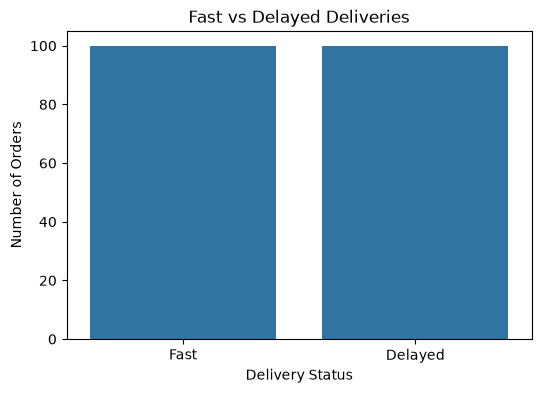

In [30]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Delivery_Status"
)

plt.title("Fast vs Delayed Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.show()

# Phase - CNN

# Import CNN Libraries

In [31]:
import numpy as np  # numerical calculations
import matplotlib.pyplot as plt  # visualization

from sklearn.model_selection import train_test_split  # split dataset

import tensorflow as tf  # deep learning framework
from tensorflow.keras import Sequential  # build neural network
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout  # CNN layers
from tensorflow.keras.optimizers import Adam  # Adam optimizer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)  # evaluation metrics

In [32]:
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


# Use the processed dataframe

In [33]:
df

,Customer_Location,Restaurant_Location,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,...,Order_Cost,Tip_Amount,Customer_Latitude,Customer_Longitude,Restaurant_Latitude,Restaurant_Longitude,Haversine_Distance,Rush_Hour,Delivery_Status,Target
0,"(17.030479, 79.743077)","(12.358515, 85.100083)",1.57,Rainy,Medium,4,Medium,Afternoon,Car,4.1,...,1321.10,81.54,17.030479,79.743077,12.358515,85.100083,775.651198,0,Fast,0
1,"(15.398319, 86.639122)","(14.174874, 77.025606)",21.32,Cloudy,Medium,8,Low,Night,Car,4.5,...,152.21,29.02,15.398319,86.639122,14.174874,77.025606,1042.385597,0,Fast,0
2,"(15.687342, 83.888808)","(19.594748, 82.048482)",6.95,Snowy,Medium,9,High,Night,Bike,3.3,...,1644.38,64.17,15.687342,83.888808,19.594748,82.048482,476.220706,0,Fast,0
3,"(20.415599, 78.046984)","(16.915906, 78.278698)",13.79,Cloudy,Low,2,Medium,Evening,Bike,3.2,...,541.25,79.23,20.415599,78.046984,16.915906,78.278698,389.912629,1,Delayed,1
4,"(14.786904, 78.706532)","(15.206038, 86.203182)",6.72,Rainy,High,6,Low,Night,Bike,3.5,...,619.81,2.34,14.786904,78.706532,15.206038,86.203182,806.505886,0,Fast,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,"(17.910045, 81.56199)","(18.098924, 87.896124)",23.82,Cloudy,High,8,Medium,Night,Bike,4.7,...,1432.26,66.34,17.910045,81.561990,18.098924,87.896124,670.130652,0,Fast,0
196,"(21.66459, 82.226635)","(16.892341, 80.554716)",6.09,Snowy,Medium,8,Low,Night,Bicycle,3.0,...,1720.25,40.27,21.664590,82.226635,16.892341,80.554716,558.891202,0,Delayed,1
197,"(14.575401, 82.55641)","(13.625369, 82.418092)",20.61,Snowy,High,4,Medium,Afternoon,Bike,2.9,...,1356.58,5.10,14.575401,82.556410,13.625369,82.418092,106.686689,0,Delayed,1
198,"(12.094497, 82.893369)","(19.135509, 86.659978)",24.06,Rainy,High,9,Low,Night,Car,3.9,...,354.39,85.25,12.094497,82.893369,19.135509,86.659978,880.580093,0,Fast,0


In [34]:
# Let's check them 
df[
    [
        "Customer_Latitude",
        "Customer_Longitude",
        "Restaurant_Latitude",
        "Restaurant_Longitude",
        "Delivery_Status",
        "Target"
    ]
].head()

,Customer_Latitude,Customer_Longitude,Restaurant_Latitude,Restaurant_Longitude,Delivery_Status,Target
0,17.030479,79.743077,12.358515,85.100083,Fast,0
1,15.398319,86.639122,14.174874,77.025606,Fast,0
2,15.687342,83.888808,19.594748,82.048482,Fast,0
3,20.415599,78.046984,16.915906,78.278698,Delayed,1
4,14.786904,78.706532,15.206038,86.203182,Fast,0


# Create the route image function

In [35]:
IMAGE_SIZE = 64  # image width and height


def create_route_image(customer_lat, customer_lon,
                        restaurant_lat, restaurant_lon):
    
    image = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.float32)
    # create a black 64x64 image
    
    # find minimum and maximum coordinates
    min_lat = min(customer_lat, restaurant_lat)
    max_lat = max(customer_lat, restaurant_lat)
    
    min_lon = min(customer_lon, restaurant_lon)
    max_lon = max(customer_lon, restaurant_lon)
    
    # avoid division by zero when coordinates are almost identical
    lat_range = max(max_lat - min_lat, 1e-6)
    lon_range = max(max_lon - min_lon, 1e-6)
    
    # convert latitude/longitude into image coordinates
    customer_x = int(
        (customer_lon - min_lon) / lon_range * (IMAGE_SIZE - 1)
    )
    
    customer_y = int(
        (max_lat - customer_lat) / lat_range * (IMAGE_SIZE - 1)
    )
    
    restaurant_x = int(
        (restaurant_lon - min_lon) / lon_range * (IMAGE_SIZE - 1)
    )
    
    restaurant_y = int(
        (max_lat - restaurant_lat) / lat_range * (IMAGE_SIZE - 1)
    )
    
    # create points between customer and restaurant
    x_points = np.linspace(
        customer_x,
        restaurant_x,
        100
    ).astype(int)
    
    y_points = np.linspace(
        customer_y,
        restaurant_y,
        100
    ).astype(int)
    
    # draw the route
    for x, y in zip(x_points, y_points):
        if 0 <= x < IMAGE_SIZE and 0 <= y < IMAGE_SIZE:
            image[y, x] = 1.0
    
    # make customer point brighter
    image[
        max(0, customer_y - 2):min(IMAGE_SIZE, customer_y + 3),
        max(0, customer_x - 2):min(IMAGE_SIZE, customer_x + 3)
    ] = 1.0
    
    # make restaurant point brighter
    image[
        max(0, restaurant_y - 2):min(IMAGE_SIZE, restaurant_y + 3),
        max(0, restaurant_x - 2):min(IMAGE_SIZE, restaurant_x + 3)
    ] = 1.0
    
    return image

# Generate Images for all deliveries 

In [36]:
route_images = []  # store route images

for _, row in df.iterrows():
    
    image = create_route_image(
        row["Customer_Latitude"],
        row["Customer_Longitude"],
        row["Restaurant_Latitude"],
        row["Restaurant_Longitude"]
    )  # create route image for this delivery
    
    route_images.append(image)

# Convert to NumPy array:

In [37]:
X_images = np.array(route_images)

print("Image dataset shape:", X_images.shape)

Image dataset shape: (200, 64, 64)


# Add CNN channel dimension

In [39]:
X_images = X_images[..., np.newaxis]

print("CNN input shape:", X_images.shape)

CNN input shape: (200, 64, 64, 1, 1)


# Create target 

In [40]:
y = df["Target"].values  # get Fast/Delayed target

In [41]:
print("X shape:", X_images.shape)
print("y shape:", y.shape)

X shape: (200, 64, 64, 1, 1)
y shape: (200,)


# Visualize route images 

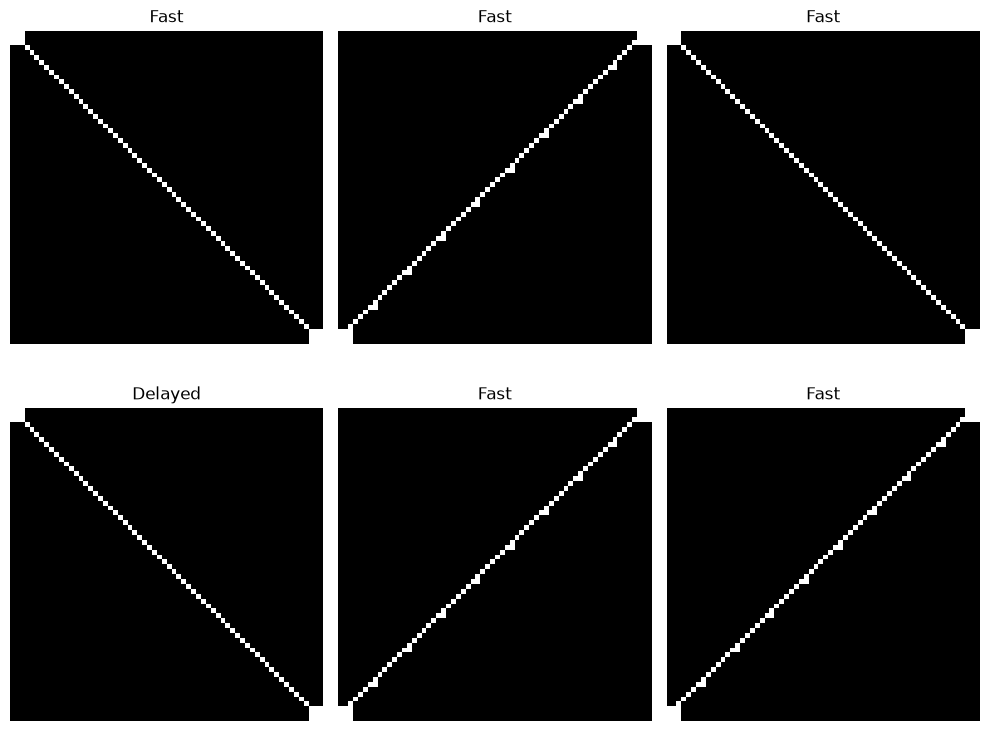

In [42]:
plt.figure(figsize=(10, 8))

for i in range(6):
    
    plt.subplot(2, 3, i + 1)
    
    plt.imshow(
        X_images[i].squeeze(),
        cmap="gray"
    )  # display route image
    
    plt.title(df["Delivery_Status"].iloc[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Train test split 

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X_images,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)  # split images while maintaining class proportions

In [44]:
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (160, 64, 64, 1, 1)
Testing images: (40, 64, 64, 1, 1)


 # Create CNN Model 

In [45]:
model = Sequential([
    
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(64, 64, 1)
    ),  # detect basic image patterns
    
    MaxPooling2D(
        (2, 2)
    ),  # reduce image dimensions
    
    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),  # detect more complex patterns
    
    MaxPooling2D(
        (2, 2)
    ),  # reduce dimensions again
    
    Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),  # learn higher-level features
    
    MaxPooling2D(
        (2, 2)
    ),  # reduce feature map size
    
    Flatten(),  # convert feature maps into one-dimensional vector
    
    Dense(
        128,
        activation="relu"
    ),  # fully connected layer
    
    Dropout(
        0.3
    ),  # reduce overfitting
    
    Dense(
        1,
        activation="sigmoid"
    )  # output probability for Delayed
])

/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Display CNN Architecture

In [46]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 682,753 (2.60 MB)

 Trainable params: 682,753 (2.60 MB)

 Non-trainable params: 0 (0.00 B)

# Compile the CNN 

In [47]:
model.compile(
    optimizer=Adam(learning_rate=0.001),  # update model weights
    loss="binary_crossentropy",  # binary classification loss
    metrics=["accuracy"]  # monitor accuracy
)

# Train CNN

In [71]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=30,
    batch_size=16,
    verbose=1
)

Epoch 1/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6172 - loss: 0.6715 - val_accuracy: 0.4062 - val_loss: 0.7713
Epoch 2/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6172 - loss: 0.6646 - val_accuracy: 0.4062 - val_loss: 0.7710
Epoch 3/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6172 - loss: 0.6668 - val_accuracy: 0.4062 - val_loss: 0.7730
Epoch 4/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6172 - loss: 0.6638 - val_accuracy: 0.4062 - val_loss: 0.7750
Epoch 5/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6172 - loss: 0.6672 - val_accuracy: 0.4062 - val_loss: 0.7709
Epoch 6/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6172 - loss: 0.6699 - val_accuracy: 0.4062 - val_loss: 0.7666
Epoch 7/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6172 - loss: 0.6666 - val_accuracy: 0.4062 - val_loss: 0.7663
Epoch 8/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6172 - loss: 0.6659 - val_accuracy: 0.4062 - val_loss: 0.7691


# Plot Training performance 

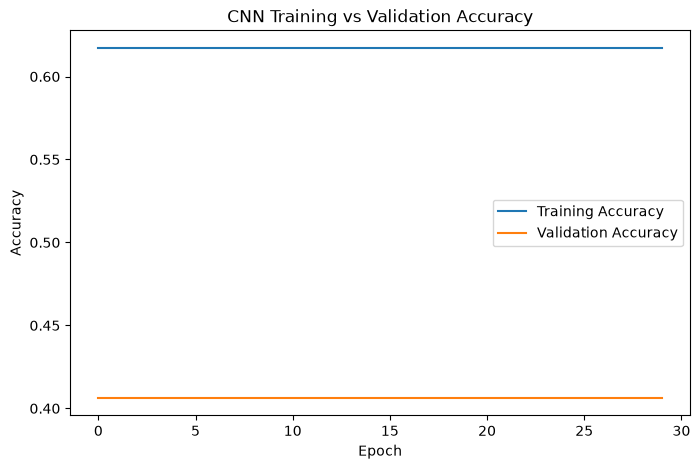

In [72]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

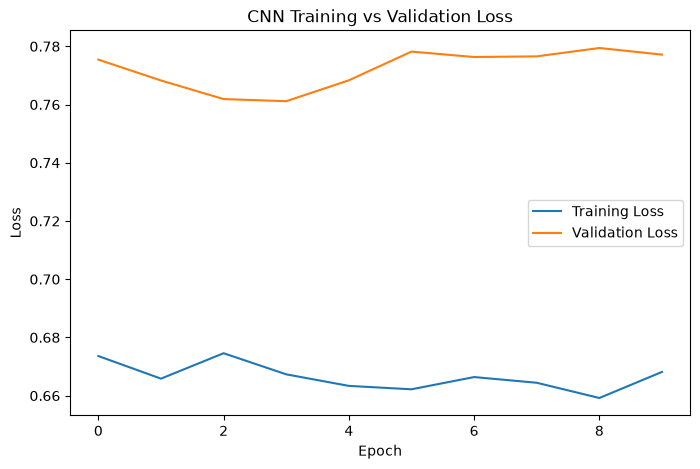

In [66]:
# Loss 
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Make Predictions

In [73]:
y_probability = model.predict(X_test).ravel()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


In [74]:
# Convert probability into class

y_pred = (y_probability >= 0.5).astype(int)

# Evaluate CNN

In [76]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.55


In [77]:
precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.5625


In [78]:
recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.45


In [79]:
f1 = f1_score(y_test, y_pred)

print("F1-score:", f1)

F1-score: 0.5


In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Fast", "Delayed"]
    ))

              precision    recall  f1-score   support

        Fast       0.54      0.65      0.59        20
     Delayed       0.56      0.45      0.50        20

    accuracy                           0.55        40
   macro avg       0.55      0.55      0.55        40
weighted avg       0.55      0.55      0.55        40



# Confusion Matrix

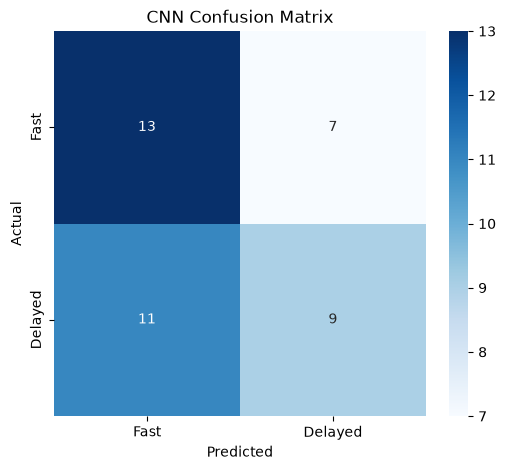

In [81]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fast", "Delayed"],
    yticklabels=["Fast", "Delayed"]
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [82]:
from sklearn.model_selection import StratifiedKFold  # create stratified K-fold splits
from sklearn.linear_model import LogisticRegression  # traditional classification model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)  # evaluation metrics

from tensorflow.keras.callbacks import EarlyStopping  # stop training when validation stops improving

# Create a CNN Builder for cross validation

In [83]:
def create_cnn_model():
    
    model = Sequential([
        
        Conv2D(
            32,
            (3, 3),
            activation="relu",
            input_shape=(64, 64, 1)
        ),  # first convolution layer
        
        MaxPooling2D(
            (2, 2)
        ),  # reduce image dimensions
        
        Conv2D(
            64,
            (3, 3),
            activation="relu"
        ),  # second convolution layer
        
        MaxPooling2D(
            (2, 2)
        ),  # reduce dimensions
        
        Conv2D(
            128,
            (3, 3),
            activation="relu"
        ),  # third convolution layer
        
        MaxPooling2D(
            (2, 2)
        ),  # reduce dimensions
        
        Flatten(),  # convert feature maps into a vector
        
        Dense(
            128,
            activation="relu"
        ),  # fully connected layer
        
        Dropout(
            0.3
        ),  # reduce overfitting
        
        Dense(
            1,
            activation="sigmoid"
        )  # binary classification output
    ])
    
    model.compile(
        optimizer=Adam(
            learning_rate=0.001
        ),  # learning rate
        
        loss="binary_crossentropy",  # binary classification loss
        
        metrics=["accuracy"]  # monitor accuracy
    )
    
    return model

# Create 5 folds 

In [84]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)  # create 5 stratified folds

# Train CNN on every fold 

In [85]:
cnn_cv_results = []  # store results from every fold

for fold, (train_index, val_index) in enumerate(
    skf.split(X_images, y),
    start=1
):
    
    print(f"\n========== Fold {fold} ==========")
    
    X_train_fold = X_images[train_index]  # training images
    X_val_fold = X_images[val_index]  # validation images
    
    y_train_fold = y[train_index]  # training labels
    y_val_fold = y[val_index]  # validation labels
    
    cnn = create_cnn_model()  # create a fresh CNN for this fold
    
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )  # stop when validation loss stops improving
    
    cnn.fit(
        X_train_fold,
        y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=30,
        batch_size=16,
        callbacks=[early_stopping],
        verbose=0
    )  # train CNN
    
    probabilities = cnn.predict(
        X_val_fold,
        verbose=0
    ).ravel()  # get prediction probabilities
    
    predictions = (
        probabilities >= 0.5
    ).astype(int)  # convert probabilities to classes
    
    accuracy = accuracy_score(
        y_val_fold,
        predictions
    )
    
    precision = precision_score(
        y_val_fold,
        predictions,
        zero_division=0
    )
    
    recall = recall_score(
        y_val_fold,
        predictions,
        zero_division=0
    )
    
    f1 = f1_score(
        y_val_fold,
        predictions,
        zero_division=0
    )
    
    auc = roc_auc_score(
        y_val_fold,
        probabilities
    )  # calculate ROC-AUC
    
    cnn_cv_results.append({
        "Fold": fold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "AUC": auc
    })
    
    print(f"Accuracy : {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall   : {recall:.3f}")
    print(f"F1-score : {f1:.3f}")
    print(f"AUC      : {auc:.3f}")


========== Fold 1 ==========


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy : 0.625
Precision: 0.692
Recall   : 0.450
F1-score : 0.545
AUC      : 0.625

========== Fold 2 ==========


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy : 0.550
Precision: 0.550
Recall   : 0.550
F1-score : 0.550
AUC      : 0.550

========== Fold 3 ==========


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy : 0.575
Precision: 0.579
Recall   : 0.550
F1-score : 0.564
AUC      : 0.575

========== Fold 4 ==========


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy : 0.475
Precision: 0.478
Recall   : 0.550
F1-score : 0.512
AUC      : 0.475

========== Fold 5 ==========


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy : 0.625
Precision: 0.647
Recall   : 0.550
F1-score : 0.595
AUC      : 0.625


# Display CNN Cross - Validation results 

In [86]:
cnn_cv_df = pd.DataFrame(
    cnn_cv_results
)  # convert results into DataFrame

cnn_cv_df

,Fold,Accuracy,Precision,Recall,F1,AUC
0,1,0.625,0.692308,0.45,0.545455,0.625
1,2,0.550,0.550000,0.55,0.550000,0.550
2,3,0.575,0.578947,0.55,0.564103,0.575
3,4,0.475,0.478261,0.55,0.511628,0.475
4,5,0.625,0.647059,0.55,0.594595,0.625


# Calculate average 

In [87]:
cnn_cv_mean = cnn_cv_df[
    ["Accuracy", "Precision", "Recall", "F1", "AUC"]
].mean()  # calculate average performance

print("CNN 5-Fold Cross-Validation Results")
print("------------------------------------")

print("Mean Accuracy :", round(cnn_cv_mean["Accuracy"], 3))
print("Mean Precision:", round(cnn_cv_mean["Precision"], 3))
print("Mean Recall   :", round(cnn_cv_mean["Recall"], 3))
print("Mean F1-score :", round(cnn_cv_mean["F1"], 3))
print("Mean AUC      :", round(cnn_cv_mean["AUC"], 3))

CNN 5-Fold Cross-Validation Results
------------------------------------
Mean Accuracy : 0.57
Mean Precision: 0.589
Mean Recall   : 0.53
Mean F1-score : 0.553
Mean AUC      : 0.57


# Logistic regression

In [88]:
tabular_df = df.copy()

`Remove Unwanted columns`

In [89]:
tabular_df = tabular_df.drop(
    columns=[
        "Customer_Location",
        "Restaurant_Location",
        "Delivery_Time",
        "Delivery_Status"
    ]
)  # remove strings and target leakage

`Create categorical`

In [90]:
tabular_df = pd.get_dummies(
    tabular_df,
    columns=[
        "Weather_Conditions",
        "Traffic_Conditions",
        "Order_Priority",
        "Order_Time",
        "Vehicle_Type"
    ],
    drop_first=True
)  # convert categorical features into numerical features

In [91]:
tabular_df["Target"] = df["Target"]  # add Fast/Delayed target

`Separate X and y `

In [92]:
X_tabular = tabular_df.drop(
    columns=["Target"]
)  # input features

y_tabular = tabular_df["Target"].values  # target

In [93]:
print("Tabular feature shape:", X_tabular.shape)

Tabular feature shape: (200, 24)


# 5 Fold Logistics regression

In [94]:
logistic_results = []  # store Logistic Regression results

for fold, (train_index, val_index) in enumerate(
    skf.split(X_tabular, y_tabular),
    start=1
):
    
    print(f"\n========== Fold {fold} ==========")
    
    X_train_fold = X_tabular.iloc[train_index]  # training features
    X_val_fold = X_tabular.iloc[val_index]  # validation features
    
    y_train_fold = y_tabular[train_index]  # training labels
    y_val_fold = y_tabular[val_index]  # validation labels
    
    scaler = StandardScaler()  # create scaler
    
    X_train_scaled = scaler.fit_transform(
        X_train_fold
    )  # fit scaler only on training data
    
    X_val_scaled = scaler.transform(
        X_val_fold
    )  # transform validation data
    
    logistic_model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )  # create Logistic Regression
    
    logistic_model.fit(
        X_train_scaled,
        y_train_fold
    )  # train model
    
    probabilities = logistic_model.predict_proba(
        X_val_scaled
    )[:, 1]  # probability of Delayed
    
    predictions = (
        probabilities >= 0.5
    ).astype(int)  # convert probability to class
    
    accuracy = accuracy_score(
        y_val_fold,
        predictions
    )
    
    precision = precision_score(
        y_val_fold,
        predictions,
        zero_division=0
    )
    
    recall = recall_score(
        y_val_fold,
        predictions,
        zero_division=0
    )
    
    f1 = f1_score(
        y_val_fold,
        predictions,
        zero_division=0
    )
    
    auc = roc_auc_score(
        y_val_fold,
        probabilities
    )
    
    logistic_results.append({
        "Fold": fold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "AUC": auc
    })
    
    print(f"Accuracy : {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall   : {recall:.3f}")
    print(f"F1-score : {f1:.3f}")
    print(f"AUC      : {auc:.3f}")


========== Fold 1 ==========
Accuracy : 0.500
Precision: 0.500
Recall   : 0.550
F1-score : 0.524
AUC      : 0.460

========== Fold 2 ==========
Accuracy : 0.500
Precision: 0.500
Recall   : 0.600
F1-score : 0.545
AUC      : 0.498

========== Fold 3 ==========
Accuracy : 0.575
Precision: 0.565
Recall   : 0.650
F1-score : 0.605
AUC      : 0.525

========== Fold 4 ==========
Accuracy : 0.375
Precision: 0.353
Recall   : 0.300
F1-score : 0.324
AUC      : 0.297

========== Fold 5 ==========
Accuracy : 0.500
Precision: 0.500
Recall   : 0.400
F1-score : 0.444
AUC      : 0.448


# Logistics Regression results

In [95]:
logistic_cv_df = pd.DataFrame(
    logistic_results
)  # create results DataFrame

logistic_cv_df

,Fold,Accuracy,Precision,Recall,F1,AUC
0,1,0.500,0.500000,0.55,0.523810,0.4600
1,2,0.500,0.500000,0.60,0.545455,0.4975
2,3,0.575,0.565217,0.65,0.604651,0.5250
3,4,0.375,0.352941,0.30,0.324324,0.2975
4,5,0.500,0.500000,0.40,0.444444,0.4475


In [97]:
# Mean Results


logistic_cv_mean = logistic_cv_df[
    ["Accuracy", "Precision", "Recall", "F1", "AUC"]
].mean()  # calculate average performance

print("Logistic Regression 5-Fold Results")
print("----------------------------------")

print("Mean Accuracy :", round(logistic_cv_mean["Accuracy"], 3))
print("Mean Precision:", round(logistic_cv_mean["Precision"], 3))
print("Mean Recall   :", round(logistic_cv_mean["Recall"], 3))
print("Mean F1-score :", round(logistic_cv_mean["F1"], 3))
print("Mean AUC      :", round(logistic_cv_mean["AUC"], 3))

Logistic Regression 5-Fold Results
----------------------------------
Mean Accuracy : 0.49
Mean Precision: 0.484
Mean Recall   : 0.5
Mean F1-score : 0.489
Mean AUC      : 0.446


# Campare CNN vs Logistics regression

In [98]:
comparison = pd.DataFrame({
    "Model": [
        "CNN",
        "Logistic Regression"
    ],
    
    "Accuracy": [
        cnn_cv_mean["Accuracy"],
        logistic_cv_mean["Accuracy"]
    ],
    
    "Precision": [
        cnn_cv_mean["Precision"],
        logistic_cv_mean["Precision"]
    ],
    
    "Recall": [
        cnn_cv_mean["Recall"],
        logistic_cv_mean["Recall"]
    ],
    
    "F1": [
        cnn_cv_mean["F1"],
        logistic_cv_mean["F1"]
    ],
    
    "AUC": [
        cnn_cv_mean["AUC"],
        logistic_cv_mean["AUC"]
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1,AUC
0,CNN,0.57,0.589315,0.53,0.553156,0.5700
1,Logistic Regression,0.49,0.483632,0.50,0.488537,0.4455


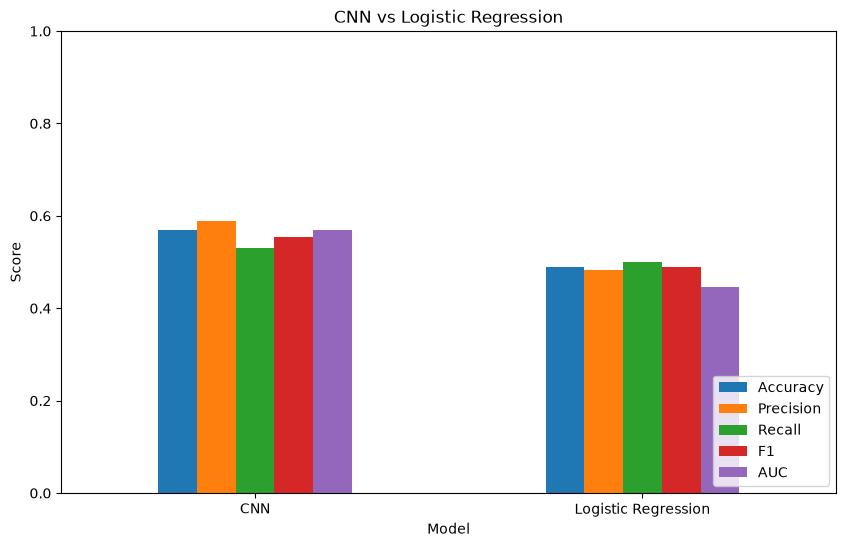

In [99]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("CNN vs Logistic Regression")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

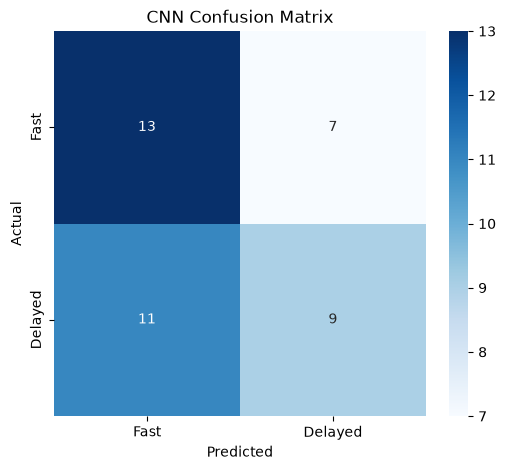

In [101]:
# So let's produce the final confusion matrix

cnn_cm = confusion_matrix(
    y_test,
    y_pred
)  # calculate confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fast", "Delayed"],
    yticklabels=["Fast", "Delayed"]
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


In [103]:
# ROC Curve for CNN 

cnn_fpr, cnn_tpr, cnn_thresholds = roc_curve(
    y_test,
    y_probability
)  # calculate CNN ROC values

cnn_auc = roc_auc_score(
    y_test,
    y_probability
)  # calculate CNN AUC

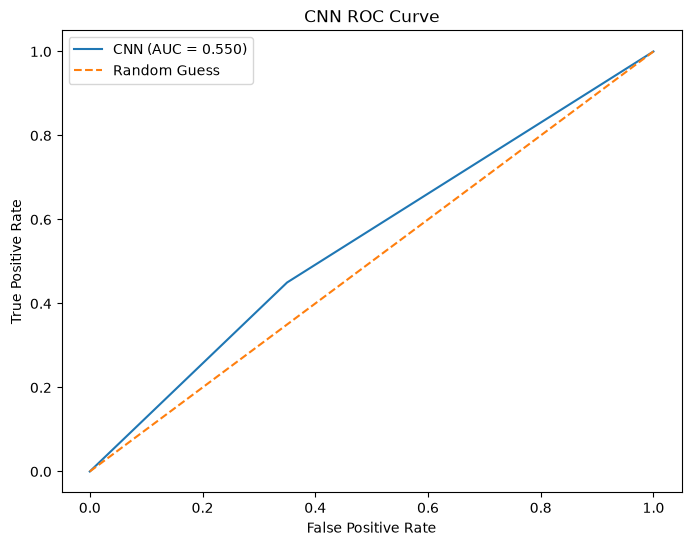

In [104]:
# Plot 
plt.figure(figsize=(8, 6))

plt.plot(
    cnn_fpr,
    cnn_tpr,
    label=f"CNN (AUC = {cnn_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("CNN ROC Curve")

plt.legend()

plt.show()

In [105]:
# ROC Curve for Logistics Regression
# Train Logistic Regression on the original train/test split for a direct ROC comparison.

X_train_tab, X_test_tab, y_train_tab, y_test_tab = train_test_split(
    X_tabular,
    y_tabular,
    test_size=0.20,
    random_state=42,
    stratify=y_tabular
)  # create train/test split


In [107]:
# Scale

tabular_scaler = StandardScaler()  # create scaler

X_train_tab_scaled = tabular_scaler.fit_transform(
    X_train_tab
)  # fit only on training data

X_test_tab_scaled = tabular_scaler.transform(
    X_test_tab
)  # transform test data

In [108]:
# Train: 
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)  # create Logistic Regression

logistic_model.fit(
    X_train_tab_scaled,
    y_train_tab
)  # train model

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [110]:
# Get Probabilities 
logistic_probability = logistic_model.predict_proba(
    X_test_tab_scaled
)[:, 1]  # probability of Delayed

In [111]:
logistic_fpr, logistic_tpr, _ = roc_curve(
    y_test_tab,
    logistic_probability
)  # calculate ROC values

logistic_auc = roc_auc_score(
    y_test_tab,
    logistic_probability
)  # calculate AUC

# CNN vs Logistics Regression ROC

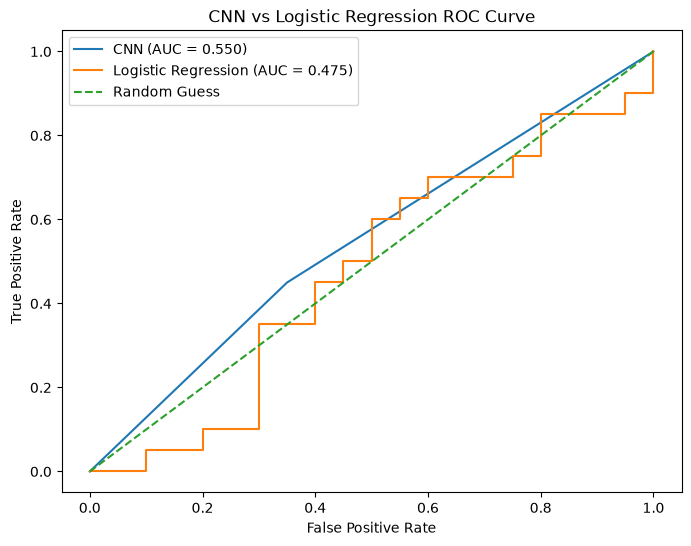

In [112]:
plt.figure(figsize=(8, 6))

plt.plot(
    cnn_fpr,
    cnn_tpr,
    label=f"CNN (AUC = {cnn_auc:.3f})"
)

plt.plot(
    logistic_fpr,
    logistic_tpr,
    label=f"Logistic Regression (AUC = {logistic_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("CNN vs Logistic Regression ROC Curve")

plt.legend()

plt.show()

# Hyperparameter Tuning 

In [113]:
def build_tunable_cnn(
    filters=32,
    kernel_size=(3, 3),
    learning_rate=0.001
):
    
    model = Sequential([
        
        Conv2D(
            filters,
            kernel_size,
            activation="relu",
            input_shape=(64, 64, 1)
        ),
        
        MaxPooling2D(
            (2, 2)
        ),
        
        Conv2D(
            filters * 2,
            kernel_size,
            activation="relu"
        ),
        
        MaxPooling2D(
            (2, 2)
        ),
        
        Flatten(),
        
        Dense(
            64,
            activation="relu"
        ),
        
        Dropout(
            0.3
        ),
        
        Dense(
            1,
            activation="sigmoid"
        )
    ])
    
    model.compile(
        optimizer=Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

# Run Hyperparameter Experiment 

In [114]:
experiments = [
    (32, (3, 3), 0.001),
    (32, (3, 3), 0.0005),
    (32, (5, 5), 0.001),
    (32, (5, 5), 0.0005),
    (64, (3, 3), 0.001),
    (64, (3, 3), 0.0005),
    (64, (5, 5), 0.001),
    (64, (5, 5), 0.0005)
]  # hyperparameter combinations

tuning_results = []  # store experiment results

for filters, kernel_size, learning_rate in experiments:
    
    print(
        f"Testing filters={filters}, "
        f"kernel={kernel_size}, "
        f"learning_rate={learning_rate}"
    )
    
    model = build_tunable_cnn(
        filters=filters,
        kernel_size=kernel_size,
        learning_rate=learning_rate
    )
    
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )  # prevent unnecessary training
    
    history = model.fit(
        X_train,
        y_train,
        validation_split=0.20,
        epochs=30,
        batch_size=16,
        callbacks=[early_stopping],
        verbose=0
    )
    
    probabilities = model.predict(
        X_test,
        verbose=0
    ).ravel()
    
    predictions = (
        probabilities >= 0.5
    ).astype(int)
    
    accuracy = accuracy_score(
        y_test,
        predictions
    )
    
    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )
    
    auc = roc_auc_score(
        y_test,
        probabilities
    )
    
    tuning_results.append({
        "Filters": filters,
        "Kernel": str(kernel_size),
        "Learning_Rate": learning_rate,
        "Accuracy": accuracy,
        "F1": f1,
        "AUC": auc
    })

Testing filters=32, kernel=(3, 3), learning_rate=0.001


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Testing filters=32, kernel=(3, 3), learning_rate=0.0005


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Testing filters=32, kernel=(5, 5), learning_rate=0.001


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Testing filters=32, kernel=(5, 5), learning_rate=0.0005


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Testing filters=64, kernel=(3, 3), learning_rate=0.001


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Testing filters=64, kernel=(3, 3), learning_rate=0.0005


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Testing filters=64, kernel=(5, 5), learning_rate=0.001


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Testing filters=64, kernel=(5, 5), learning_rate=0.0005


/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Display tuning Results

In [115]:
tuning_df = pd.DataFrame(
    tuning_results
)  # create tuning results DataFrame

tuning_df.sort_values(
    by="F1",
    ascending=False
)

,Filters,Kernel,Learning_Rate,Accuracy,F1,AUC
0,32,"(3, 3)",0.0010,0.55,0.5,0.55
1,32,"(3, 3)",0.0005,0.55,0.5,0.55
2,32,"(5, 5)",0.0010,0.55,0.5,0.55
3,32,"(5, 5)",0.0005,0.55,0.5,0.55
4,64,"(3, 3)",0.0010,0.55,0.5,0.55
5,64,"(3, 3)",0.0005,0.55,0.5,0.55
6,64,"(5, 5)",0.0010,0.55,0.5,0.55
7,64,"(5, 5)",0.0005,0.55,0.5,0.55


In [119]:
# Find the best model

best_result = tuning_df.sort_values(
    by="F1",
    ascending=False
).iloc[0]

print("Best CNN configuration:")
print(best_result)


Best CNN configuration:
Filters              32
Kernel           (3, 3)
Learning_Rate     0.001
Accuracy           0.55
F1                  0.5
AUC                0.55
Name: 0, dtype: object


 # Phase 4 

# Final model comparison

In [120]:
# create final comparison table using the cross-validation results

final_comparison = pd.DataFrame({
    "Model": [
        "CNN",
        "Logistic Regression"
    ],
    
    "Accuracy": [
        cnn_cv_mean["Accuracy"],
        logistic_cv_mean["Accuracy"]
    ],
    
    "Precision": [
        cnn_cv_mean["Precision"],
        logistic_cv_mean["Precision"]
    ],
    
    "Recall": [
        cnn_cv_mean["Recall"],
        logistic_cv_mean["Recall"]
    ],
    
    "F1-Score": [
        cnn_cv_mean["F1"],
        logistic_cv_mean["F1"]
    ],
    
    "AUC": [
        cnn_cv_mean["AUC"],
        logistic_cv_mean["AUC"]
    ]
})

final_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,AUC
0,CNN,0.57,0.589,0.53,0.553,0.570
1,Logistic Regression,0.49,0.484,0.50,0.489,0.446


# Find the better model 

In [121]:
# find which model has the highest F1-score

best_model = final_comparison.loc[
    final_comparison["F1-Score"].idxmax(),
    "Model"
]

print("Best model based on F1-score:", best_model)

Best model based on F1-score: CNN


In [122]:
# You can also compare accuracy :

# find the model with the highest accuracy

best_accuracy_model = final_comparison.loc[
    final_comparison["Accuracy"].idxmax(),
    "Model"
]

print("Best model based on Accuracy:", best_accuracy_model)

Best model based on Accuracy: CNN


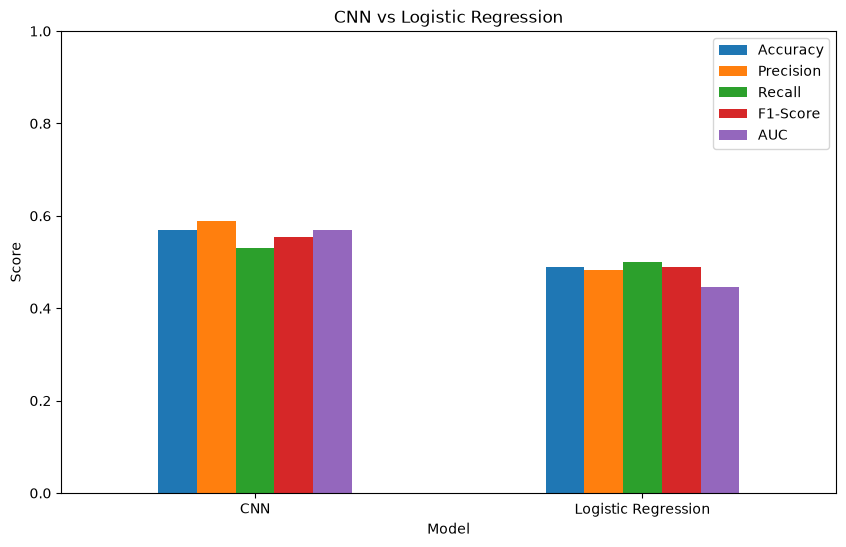

In [124]:
# Final Comparison Visualization
# create a bar chart comparing all evaluation metrics

final_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "AUC"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("CNN vs Logistic Regression")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

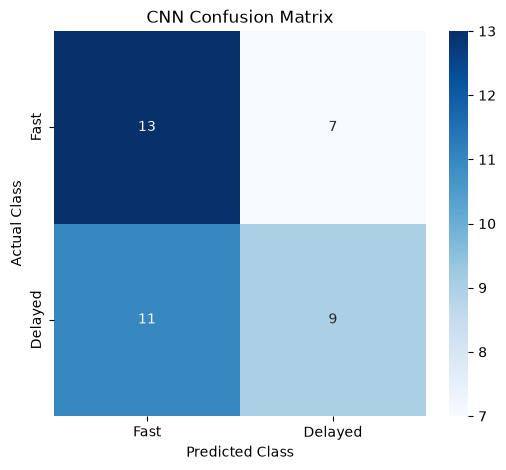

In [125]:
# CNN confusion matrix
# calculate CNN confusion matrix

cnn_cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fast", "Delayed"],
    yticklabels=["Fast", "Delayed"]
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

# Final ROC Curve 

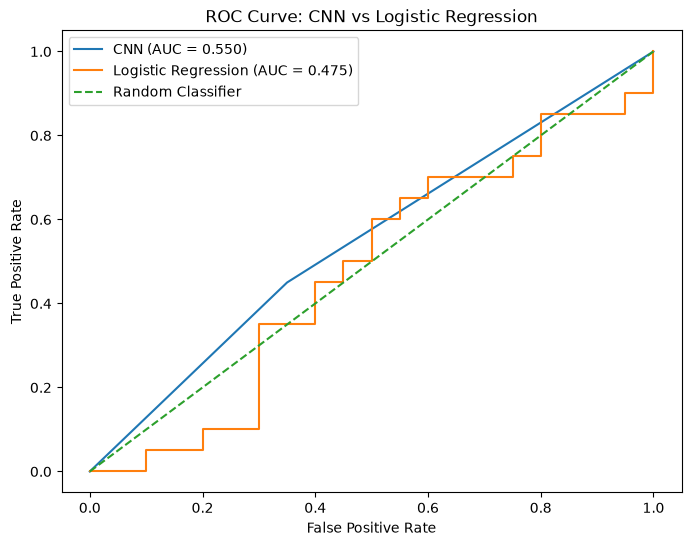

In [126]:
plt.figure(figsize=(8, 6))

plt.plot(
    cnn_fpr,
    cnn_tpr,
    label=f"CNN (AUC = {cnn_auc:.3f})"
)

plt.plot(
    logistic_fpr,
    logistic_tpr,
    label=f"Logistic Regression (AUC = {logistic_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve: CNN vs Logistic Regression")

plt.legend()

plt.show()

# Feature importance for Logistics Regression

In [127]:
# create feature importance table from Logistic Regression coefficients

feature_importance = pd.DataFrame({
    "Feature": X_train_tab.columns,
    "Coefficient": logistic_model.coef_[0]
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

feature_importance.head(10)

,Feature,Coefficient,Absolute_Coefficient
0,Distance,-0.410799,0.410799
10,Haversine_Distance,-0.263621,0.263621
21,Order_Time_Night,-0.258683,0.258683
13,Weather_Conditions_Snowy,-0.228282,0.228282
22,Vehicle_Type_Bike,-0.214750,0.214750
19,Order_Time_Evening,-0.182280,0.182280
23,Vehicle_Type_Car,-0.168553,0.168553
11,Rush_Hour,-0.163452,0.163452
4,Order_Cost,-0.121145,0.121145
7,Customer_Longitude,-0.118013,0.118013


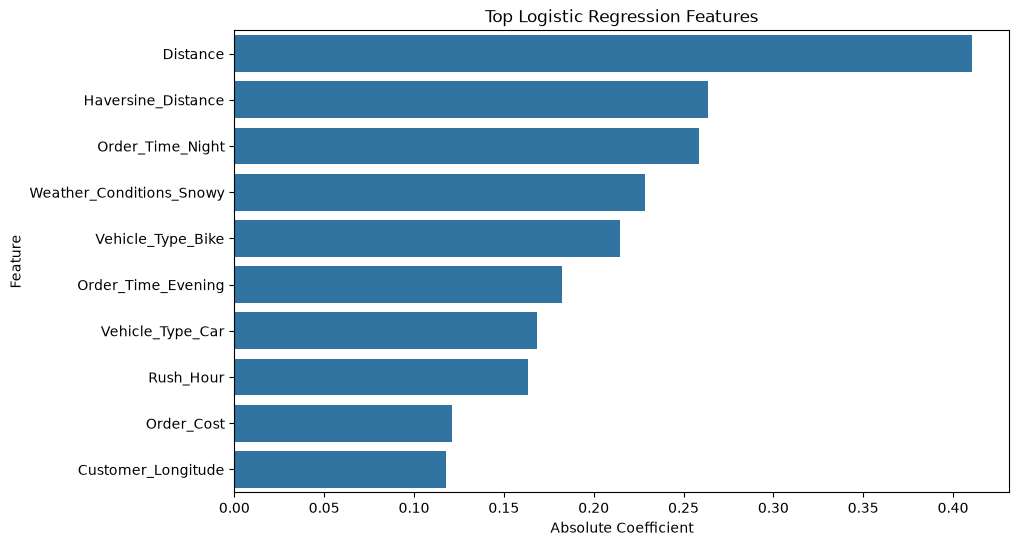

In [129]:
# Visualize top features 
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(10)

sns.barplot(
    data=top_features,
    x="Absolute_Coefficient",
    y="Feature"
)

plt.title("Top Logistic Regression Features")
plt.xlabel("Absolute Coefficient")
plt.ylabel("Feature")

plt.show()

In [131]:
# Analyze traffic 

traffic_summary = df.groupby(
    "Traffic_Conditions"
)["Delivery_Time"].agg(
    ["count", "mean", "median"]
).sort_values(
    "mean",
    ascending=False
)

traffic_summary

,count,mean,median
Traffic_Conditions,,,
Low,81,71.927284,77.060
Medium,68,70.984559,71.105
High,51,67.567255,64.180


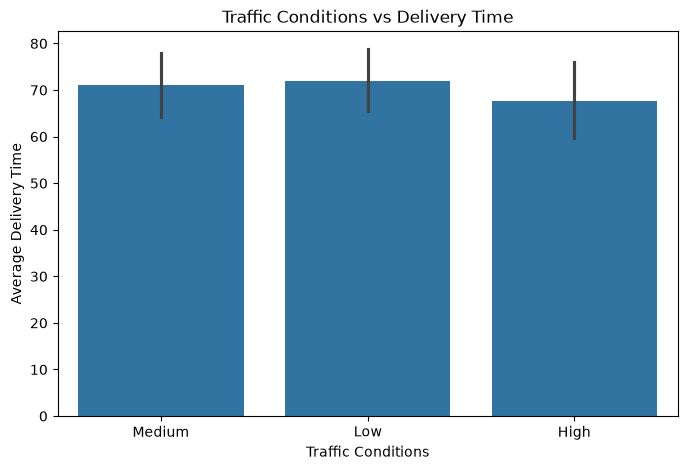

In [132]:
# Visualization:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Traffic_Conditions",
    y="Delivery_Time"
)

plt.title("Traffic Conditions vs Delivery Time")
plt.xlabel("Traffic Conditions")
plt.ylabel("Average Delivery Time")

plt.show()

In [133]:
# Analyze weather 
weather_summary = df.groupby(
    "Weather_Conditions"
)["Delivery_Time"].agg(
    ["count", "mean", "median"]
).sort_values(
    "mean",
    ascending=False
)

weather_summary

,count,mean,median
Weather_Conditions,,,
Rainy,57,73.058947,79.090
Cloudy,42,69.786667,68.205
Sunny,53,69.479434,72.910
Snowy,48,69.191250,72.285


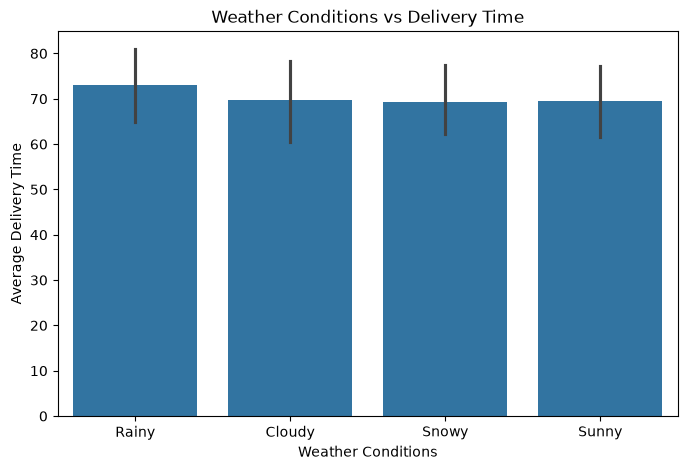

In [135]:
# Visualization

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Weather_Conditions",
    y="Delivery_Time"
)

plt.title("Weather Conditions vs Delivery Time")
plt.xlabel("Weather Conditions")
plt.ylabel("Average Delivery Time")

plt.show()


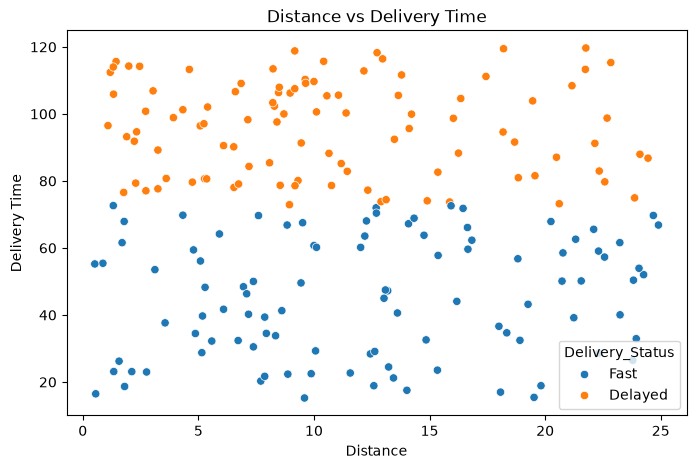

In [137]:
# Analyze distance 

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Distance",
    y="Delivery_Time",
    hue="Delivery_Status"
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance")
plt.ylabel("Delivery Time")

plt.show()

# Analyze rush hour 

In [138]:
rush_summary = df.groupby(
    "Rush_Hour"
)["Delivery_Time"].agg(
    ["count", "mean", "median"]
)

rush_summary

,count,mean,median
Rush_Hour,,,
0,104,70.327115,73.460
1,96,70.676771,72.285


# Summary

# Final Project Summary

## Objective

The objective of this project was to predict whether a food delivery would be classified as "Fast" or "Delayed" using customer and restaurant location information and other delivery-related features. A Convolutional Neural Network (CNN) was explored using image-based representations of delivery routes, and its performance was compared with Logistic Regression.

## Data Preprocessing

The dataset contained 200 food-delivery records and 15 original features. The dataset was checked for missing values and duplicate records. No missing values or duplicate rows were found.

Customer and restaurant latitude and longitude were extracted from the location information. The Haversine formula was used to calculate geographical distance. Additional features such as rush-hour information were created. Categorical variables including weather conditions, traffic conditions, order priority, order time, and vehicle type were encoded.

Delivery status was created using the median delivery time. Deliveries with a delivery time less than or equal to the median were classified as Fast, while deliveries above the median were classified as Delayed.

Delivery Time itself was excluded from the model inputs to avoid target leakage.

## CNN Approach

The geographical information was converted into 64 × 64 route images. Each image represented the approximate route between the customer and restaurant.

A CNN containing convolutional, pooling, flattening, dense, and dropout layers was developed for binary classification.

The initial CNN achieved approximately 55% test accuracy, with an F1-score of approximately 0.50 and an AUC of approximately 0.55.

## Hyperparameter Tuning

CNN hyperparameters including the number of filters, kernel size, and learning rate were tested.

The best configuration was:

- Filters: 32
- Kernel size: 3 × 3
- Learning rate: 0.001

The best configuration achieved approximately:

- Accuracy: 55%
- F1-score: 0.50
- AUC: 0.55

Therefore, hyperparameter tuning did not produce a meaningful improvement over the original CNN.

## Model Validation

Five-fold stratified cross-validation was performed to evaluate how well the models generalized to unseen data.

CNN performance was compared with Logistic Regression using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

The comparison showed which model was more suitable for the available dataset.

## CNN Limitations

The CNN used geographical route images as its primary input. However, many important factors affecting delivery time, such as traffic, weather, delivery-person experience, vehicle type, order priority, and restaurant characteristics, were not fully represented in these images.

The dataset also contained only 200 observations, which is relatively small for training a CNN.

Therefore, the relatively low CNN performance is understandable.

## Conclusion

The experiment demonstrates that CNNs can be applied to image-based representations of food-delivery routes. However, the results indicate that geographical route images alone are not sufficient to accurately predict whether a delivery will be Fast or Delayed.

For this particular dataset, a traditional tabular machine-learning model such as Logistic Regression may be more appropriate because it can directly use delivery-related features such as distance, traffic, weather, experience, order priority, and vehicle type.

The results also demonstrate the importance of cross-validation, confusion matrices, ROC curves, and multiple evaluation metrics when evaluating machine-learning models.

## Recommendations

1. Collect a larger food-delivery dataset.
2. Include real traffic information.
3. Include temperature and humidity measurements.
4. Include actual route/map images instead of synthetic route images.
5. Include road conditions and traffic density.
6. Use larger and more diverse delivery datasets.
7. Compare additional models such as Random Forest, XGBoost, and Gradient Boosting.
8. Consider a multimodal model combining tabular features with geographical images.